In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.gridspec import GridSpec
import os
from tqdm.autonotebook import tqdm

C:\Users\Administrator\AppData\Local\Temp\ipykernel_46304\3698173009.py:6: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
names = locals()

In [3]:
df_cement_production = pd.read_csv('../data/production-142.csv', index_col=0)
economies_142 = df_cement_production.columns.tolist()

In [4]:
def compile_global_values_his(the_var):
    country_values = []
    with tqdm(economies_142, desc='compiling data') as pbar:
        for country in pbar:
            pbar.set_postfix_str(f'country={country}')

            data1 = np.load(f'../results/material-flows/historical-uncertainty/{country}-1.npz', allow_pickle=True)
            data2 = np.load(f'../results/material-flows/historical-uncertainty/{country}-2.npz', allow_pickle=True)
            
            value_array = np.vstack([data1[the_var], data2[the_var]])
            country_values.append(np.percentile(value_array, [2.5, 50, 97.5], axis=0))
    
    return country_values


In [5]:
def compile_global_values_fut(scenario, the_var):
    country_values = []
    for country in tqdm(economies_142):
        a_path = f'../results/material-flows/future-uncertainty/{country}/{scenario}/{the_var}.npz'
        value_array = np.load(a_path)['array']
        selected_values = np.percentile(value_array, [2.5, 50, 97.5], axis=0)

        if selected_values.shape[1] > 28:
            country_values.append(selected_values[:, 1:])
        else:
            country_values.append(selected_values)

    return country_values

In [6]:
sand_extraction_his_set = compile_global_values_his('sand_extraction')

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

In [7]:
gravel_extraction_his_set = compile_global_values_his('gravel_extraction')
limestone_extraction_his_set = compile_global_values_his('limestone_extraction')
S_coarse_annual_his_set = compile_global_values_his('S_coarse_annual')
S_fine_annual_his_set = compile_global_values_his('S_fine_annual')
S_binder_annual_his_set = compile_global_values_his('S_binder_annual')
S_concrete_annual_his_set = compile_global_values_his('S_concrete_annual')
S_mortar_annual_his_set = compile_global_values_his('S_mortar_annual')
S_fine_for_concrete_annual_his_set = compile_global_values_his('S_fine_for_concrete_annual')
S_fine_for_mortar_annual_his_set = compile_global_values_his('S_fine_for_mortar_annual')
O_concrete_annual_his_set = compile_global_values_his('O_concrete_annual')
O_mortar_annual_his_set = compile_global_values_his('O_mortar_annual')

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

...

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

In [8]:
O_coarse_annual_his_set = compile_global_values_his('O_coarse_annual')
O_fine_annual_his_set = compile_global_values_his('O_fine_annual')

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

compiling data:   0%|          | 0/142 [00:00<?, ?it/s]

In [9]:
sand_extraction_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
sand_extraction_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
sand_extraction_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

gravel_extraction_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
gravel_extraction_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
gravel_extraction_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

limestone_extraction_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
limestone_extraction_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
limestone_extraction_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_concrete_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_concrete_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_concrete_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

S_mortar_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_mortar_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_mortar_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

S_coarse_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_coarse_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_coarse_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

S_fine_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_fine_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_fine_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

S_fine_for_concrete_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_fine_for_concrete_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_fine_for_concrete_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

S_fine_for_mortar_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_fine_for_mortar_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
S_fine_for_mortar_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

In [10]:
O_concrete_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
O_concrete_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
O_concrete_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

O_mortar_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
O_mortar_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
O_mortar_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

O_coarse_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
O_coarse_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
O_coarse_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

O_fine_annual_his_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
O_fine_annual_his_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
O_fine_annual_his_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))

In [11]:
for i, country in enumerate(economies_142):
    sand_extraction_his_low[country] = sand_extraction_his_set[i][0]
    sand_extraction_his_med[country] = sand_extraction_his_set[i][1]
    sand_extraction_his_upp[country] = sand_extraction_his_set[i][2]

    gravel_extraction_his_low[country] = gravel_extraction_his_set[i][0]
    gravel_extraction_his_med[country] = gravel_extraction_his_set[i][1]
    gravel_extraction_his_upp[country] = gravel_extraction_his_set[i][2]

    limestone_extraction_his_low[country] = limestone_extraction_his_set[i][0]
    limestone_extraction_his_med[country] = limestone_extraction_his_set[i][1]
    limestone_extraction_his_upp[country] = limestone_extraction_his_set[i][2]

    S_concrete_annual_his_low[country] = S_concrete_annual_his_set[i][0]
    S_concrete_annual_his_med[country] = S_concrete_annual_his_set[i][1]
    S_concrete_annual_his_upp[country] = S_concrete_annual_his_set[i][2]

    S_mortar_annual_his_low[country] = S_mortar_annual_his_set[i][0]
    S_mortar_annual_his_med[country] = S_mortar_annual_his_set[i][1]
    S_mortar_annual_his_upp[country] = S_mortar_annual_his_set[i][2]

    S_coarse_annual_his_low[country] = S_coarse_annual_his_set[i][0]
    S_coarse_annual_his_med[country] = S_coarse_annual_his_set[i][1]
    S_coarse_annual_his_upp[country] = S_coarse_annual_his_set[i][2]

    S_fine_annual_his_low[country] = S_fine_annual_his_set[i][0]
    S_fine_annual_his_med[country] = S_fine_annual_his_set[i][1]
    S_fine_annual_his_upp[country] = S_fine_annual_his_set[i][2]

    S_fine_for_concrete_annual_his_low[country] = S_fine_for_concrete_annual_his_set[i][0]
    S_fine_for_concrete_annual_his_med[country] = S_fine_for_concrete_annual_his_set[i][1]
    S_fine_for_concrete_annual_his_upp[country] = S_fine_for_concrete_annual_his_set[i][2]

    S_fine_for_mortar_annual_his_low[country] = S_fine_for_mortar_annual_his_set[i][0]
    S_fine_for_mortar_annual_his_med[country] = S_fine_for_mortar_annual_his_set[i][1]
    S_fine_for_mortar_annual_his_upp[country] = S_fine_for_mortar_annual_his_set[i][2]

    O_concrete_annual_his_low[country] = O_concrete_annual_his_set[i][0]
    O_concrete_annual_his_med[country] = O_concrete_annual_his_set[i][1]
    O_concrete_annual_his_upp[country] = O_concrete_annual_his_set[i][2]

    O_mortar_annual_his_low[country] = O_mortar_annual_his_set[i][0]
    O_mortar_annual_his_med[country] = O_mortar_annual_his_set[i][1]
    O_mortar_annual_his_upp[country] = O_mortar_annual_his_set[i][2]

    O_coarse_annual_his_low[country] = O_coarse_annual_his_set[i][0]
    O_coarse_annual_his_med[country] = O_coarse_annual_his_set[i][1]
    O_coarse_annual_his_upp[country] = O_coarse_annual_his_set[i][2]

    O_fine_annual_his_low[country] = O_fine_annual_his_set[i][0]
    O_fine_annual_his_med[country] = O_fine_annual_his_set[i][1]
    O_fine_annual_his_upp[country] = O_fine_annual_his_set[i][2]    

In [12]:
df_1 = pd.DataFrame([], index=np.linspace(1931, 2022, 92))
df_1['limestone'] = limestone_extraction_his_med.sum(axis=1) / 1e6
df_1['sand']      = sand_extraction_his_med.sum(axis=1) / 1e6
df_1['gravel']    = gravel_extraction_his_med.sum(axis=1) / 1e6


In [13]:
df_2 = pd.DataFrame([], index=np.linspace(1931, 2022, 92))
df_2['limestone'] = limestone_extraction_his_low.sum(axis=1) / 1e6
df_2['sand']      = sand_extraction_his_low.sum(axis=1) / 1e6
df_2['gravel']    = gravel_extraction_his_low.sum(axis=1) / 1e6

In [14]:
df_3 = pd.DataFrame([], index=np.linspace(1931, 2022, 92))
df_3['limestone'] = limestone_extraction_his_upp.sum(axis=1) / 1e6
df_3['sand']      = sand_extraction_his_upp.sum(axis=1) / 1e6
df_3['gravel']    = gravel_extraction_his_upp.sum(axis=1) / 1e6

In [15]:
df_4 = pd.DataFrame([])
df_4['concrete'] = S_concrete_annual_his_med.sum(axis=1) / 1e6
df_4['concrete_l'] = S_concrete_annual_his_low.sum(axis=1) / 1e6
df_4['concrete_u'] = S_concrete_annual_his_upp.sum(axis=1) / 1e6
df_4['mortar'] = S_mortar_annual_his_med.sum(axis=1) / 1e6
df_4['mortar_l'] = S_mortar_annual_his_low.sum(axis=1) / 1e6
df_4['mortar_u'] = S_mortar_annual_his_upp.sum(axis=1) / 1e6

In [16]:
df_5 = pd.DataFrame([], columns=['concrete', 'mortar'], index=['gravel', 'sand'])

df_5.loc['gravel', 'concrete'] = S_coarse_annual_his_med.sum(axis=1).loc[2022] / 1e6
df_5.loc['sand', 'concrete'] = S_fine_for_concrete_annual_his_med.sum(axis=1).loc[2022] / 1e6
df_5.loc['sand', 'mortar'] = S_fine_for_mortar_annual_his_med.sum(axis=1).loc[2022] / 1e6

In [17]:
df_6 = pd.DataFrame([], columns=['concrete', 'mortar'], index=['gravel', 'sand'])

df_6.loc['gravel', 'concrete'] = S_coarse_annual_his_low.sum(axis=1).loc[2022] / 1e6
df_6.loc['sand', 'concrete'] = S_fine_for_concrete_annual_his_low.sum(axis=1).loc[2022] / 1e6
df_6.loc['sand', 'mortar'] = S_fine_for_mortar_annual_his_low.sum(axis=1).loc[2022] / 1e6

In [18]:
df_7 = pd.DataFrame([], columns=['concrete', 'mortar'], index=['gravel', 'sand'])

df_7.loc['gravel', 'concrete'] = S_coarse_annual_his_upp.sum(axis=1).loc[2022] / 1e6
df_7.loc['sand', 'concrete'] = S_fine_for_concrete_annual_his_upp.sum(axis=1).loc[2022] / 1e6
df_7.loc['sand', 'mortar'] = S_fine_for_mortar_annual_his_upp.sum(axis=1).loc[2022] / 1e6

In [19]:
df_4.loc[2022].values

array([420.25666894, 405.38886564, 435.47657128, 177.97695604,
       174.57631575, 181.15788076])

In [20]:
df_4.loc[2022, ['concrete_l', 'mortar_l']].values

array([405.38886564, 174.57631575])

In [21]:
df_4.loc[2022].values.tolist()

[420.2566689394531,
 405.38886563566876,
 435.4765712771731,
 177.97695604345702,
 174.5763157455932,
 181.1578807627565]

In [22]:
df_4.loc[2022, ['concrete', 'mortar']].values - df_4.loc[2022, ['concrete_l', 'mortar_l']].values

array([14.8678033,  3.4006403])

In [23]:
df_6.sum()

concrete    312.482577
mortar      112.377977
dtype: object

In [24]:
S_coarse_annual_his_low.sum(axis=1).loc[2022]

np.float64(175245427.95891723)

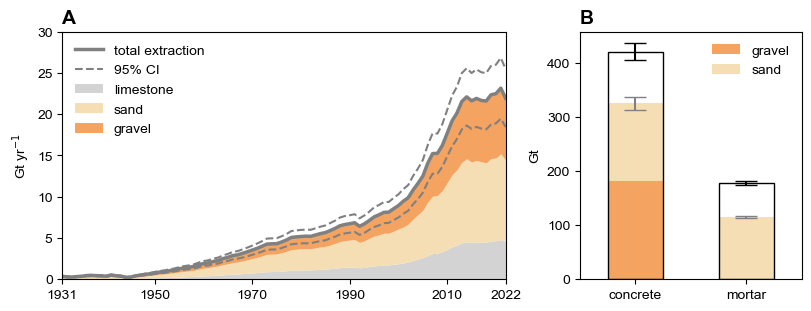

In [25]:
fig = plt.figure(figsize=(8, 3.), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'
gs = fig.add_gridspec(nrows=1, ncols=3)

ax1 = fig.add_subplot(gs[0, :2])
df_1.sum(axis=1).plot(lw=2.5, ls='-', color='grey', label='total extraction', ax=ax1)
df_2.sum(axis=1).plot(ls='--', color='grey', label='95% CI', ax=ax1)
df_3.sum(axis=1).plot(ls='--', color='grey', ax=ax1)
df_1.plot.area(stacked=True, lw=0.0, color=['lightgrey', 'wheat', 'sandybrown'], ax=ax1)
ax1.set(xlim=(1931, 2022), ylim=(0, 30), ylabel='Gt yr$^{-1}$')
ax1.set_xticks([1931, 1950, 1970, 1990, 2010, 2022])
ax1.legend(frameon=False)
ax1.set_title('A', loc='left', fontsize=14, fontweight='bold')
# ax1.spines['right'].set_visible(False)
# ax1.spines['top'].set_visible(False)

ax2 = fig.add_subplot(gs[0, 2])
df_4[['concrete', 'mortar']].loc[2022].plot.bar(lw=1.0, color='none', ec='k', zorder=5, label='', ax=ax2)
df_5.T.plot.bar(stacked=True, color=['sandybrown', 'wheat'], ax=ax2)

y_1 = df_4.loc[2022, ['concrete', 'mortar']].values
low_1 = df_4.loc[2022, ['concrete', 'mortar']].values - df_4.loc[2022, ['concrete_l', 'mortar_l']].values
high_1 = df_4.loc[2022, ['concrete_u', 'mortar_u']].values - df_4.loc[2022, ['concrete', 'mortar']].values
ax2.errorbar([0, 1], y_1, yerr=[low_1, high_1], fmt='none', capsize=8, ecolor='k')

y_2 = df_5.sum().values
low_2 = y_2 - df_6.sum()
high_2 = df_7.sum() - y_2
ax2.errorbar([0, 1], y_2, yerr=[low_2, high_2], fmt='none', capsize=8, ecolor='grey')
ax2.legend(frameon=False)
ax2.set_title('B', loc='left', fontsize=14, fontweight='bold')
ax2.set_ylabel('Gt')
ax2.set_xticklabels(['concrete', 'mortar'], rotation=0)

# ax2.spines['right'].set_visible(False)
# ax2.spines['top'].set_visible(False)

plt.show()
fig.savefig(f'../figures/Supplementary-Figuer-2.jpg', dpi=600, bbox_inches='tight')

In [26]:
df_1.loc[2022].round(1)

limestone    4.6
sand         9.9
gravel       7.5
Name: 2022.0, dtype: float64

In [27]:
df_2.loc[2022].round(1)

limestone    3.3
sand         9.0
gravel       6.1
Name: 2022.0, dtype: float64

In [28]:
df_3.loc[2022].round(1)

limestone     5.6
sand         10.7
gravel        9.1
Name: 2022.0, dtype: float64

In [29]:
df_5.sum().astype(float).round(1)

concrete    324.8
mortar      114.5
dtype: float64

In [30]:
df_6.sum().astype(float).round(1)

concrete    312.5
mortar      112.4
dtype: float64

In [31]:
df_7.sum().astype(float).round(1)

concrete    337.4
mortar      116.4
dtype: float64

future scenario results

In [32]:
sand_extraction_BAU_set = compile_global_values_fut("BAU", "sand_extraction")
sand_extraction_CE_set = compile_global_values_fut("CE", "sand_extraction")
gravel_extraction_BAU_set = compile_global_values_fut("BAU", "gravel_extraction")
gravel_extraction_CE_set = compile_global_values_fut("CE", "gravel_extraction")
limestone_extraction_BAU_set = compile_global_values_fut("BAU", "limestone_extraction")
limestone_extraction_CE_set = compile_global_values_fut("CE", "limestone_extraction")

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

In [33]:
S_coarse_annual_BAU_set = compile_global_values_fut("BAU", "S_coarse_annual")
S_coarse_annual_CE_set = compile_global_values_fut("CE", "S_coarse_annual")

S_fine_annual_BAU_set = compile_global_values_fut("BAU", "S_fine_annual")
S_fine_annual_CE_set = compile_global_values_fut("CE", "S_fine_annual")

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

In [34]:
O_coarse_annual_BAU_set = compile_global_values_fut("BAU", "O_coarse_annual")
O_coarse_annual_CE_set = compile_global_values_fut("CE", "O_coarse_annual")

O_fine_annual_BAU_set = compile_global_values_fut("BAU", "O_fine_annual")
O_fine_annual_CE_set = compile_global_values_fut("CE", "O_fine_annual")

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

  0%|          | 0/142 [00:00<?, ?it/s]

In [35]:
def compile_into_tables(value_set, type_):
    if type_ == "historical":
        df_low = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
        df_med = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
        df_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(1931, 2022, 92))
    
    elif type_ == "future":
        df_low = pd.DataFrame([], columns=economies_142, index=np.linspace(2023, 2050, 28))
        df_med = pd.DataFrame([], columns=economies_142, index=np.linspace(2023, 2050, 28))
        df_upp = pd.DataFrame([], columns=economies_142, index=np.linspace(2023, 2050, 28))

    for i, country in enumerate(economies_142):
        df_low[country] = value_set[i][0]
        df_med[country] = value_set[i][1]
        df_upp[country] = value_set[i][2]
    
    return df_low, df_med, df_upp

In [36]:
sand_extraction_BAU_low, sand_extraction_BAU_med, sand_extraction_BAU_upp = compile_into_tables(sand_extraction_BAU_set, 'future')
sand_extraction_CE_low, sand_extraction_CE_med, sand_extraction_CE_upp = compile_into_tables(sand_extraction_CE_set, 'future')


gravel_extraction_BAU_low, gravel_extraction_BAU_med, gravel_extraction_BAU_upp = compile_into_tables(gravel_extraction_BAU_set, 'future')
gravel_extraction_CE_low, gravel_extraction_CE_med, gravel_extraction_CE_upp = compile_into_tables(gravel_extraction_CE_set, 'future')

limestone_extraction_BAU_low, limestone_extraction_BAU_med, limestone_extraction_BAU_upp = compile_into_tables(limestone_extraction_BAU_set, 'future')
limestone_extraction_CE_low, limestone_extraction_CE_med, limestone_extraction_CE_upp = compile_into_tables(limestone_extraction_CE_set, 'future')


In [37]:
S_coarse_annual_BAU_low, S_coarse_annual_BAU_med, S_coarse_annual_BAU_upp = compile_into_tables(S_coarse_annual_BAU_set, 'future')
S_coarse_annual_CE_low, S_coarse_annual_CE_med, S_coarse_annual_CE_upp = compile_into_tables(S_coarse_annual_CE_set, 'future')

S_fine_annual_BAU_low, S_fine_annual_BAU_med, S_fine_annual_BAU_upp = compile_into_tables(S_fine_annual_BAU_set, 'future')
S_fine_annual_CE_low, S_fine_annual_CE_med, S_fine_annual_CE_upp = compile_into_tables(S_fine_annual_CE_set, 'future')

In [38]:
O_coarse_annual_BAU_low, O_coarse_annual_BAU_med, O_coarse_annual_BAU_upp = compile_into_tables(O_coarse_annual_BAU_set, 'future')
O_coarse_annual_CE_low, O_coarse_annual_CE_med, O_coarse_annual_CE_upp = compile_into_tables(O_coarse_annual_CE_set, 'future')

O_fine_annual_BAU_low, O_fine_annual_BAU_med, O_fine_annual_BAU_upp = compile_into_tables(O_fine_annual_BAU_set, 'future')
O_fine_annual_CE_low, O_fine_annual_CE_med, O_fine_annual_CE_upp = compile_into_tables(O_fine_annual_CE_set, 'future')

In main text

In [39]:
a = 

SyntaxError: invalid syntax (2792523948.py, line 1)

In [ ]:
df_1.loc[2022].sum()

np.float64(21.930509249897003)

In [ ]:
df_5.sum()['concrete']

np.float64(324.77047486340336)

In [ ]:
a_1 = df_1.loc[2022].sum()
a_2 = df_2.loc[2022].sum()
a_3 = df_3.loc[2022].sum()
a_4 = df_1.loc[2022, 'sand']
a_5 = df_2.loc[2022, 'sand']
a_6 = df_3.loc[2022, 'sand']
a_7 = df_1.loc[2022, 'gravel']
a_8 = df_2.loc[2022, 'gravel']
a_9 = df_3.loc[2022, 'gravel']
a_10 = df_1.loc[2022, 'limestone']
a_11 = df_2.loc[2022, 'limestone']
a_12 = df_3.loc[2022, 'limestone']
a_13 = df_5.sum()['concrete']
a_14 = df_6.sum()['concrete']
a_15 = df_7.sum()['concrete']
a_16 = df_5.sum()['mortar']
a_17 = df_6.sum()['mortar']
a_18 = df_7.sum()['mortar']

print(f'Our historical accounting shows that global extraction of construction aggregates \n\
embodied in concrete and mortar reached {a_1:.1f} Gt yr-1 (95% confidence interval (CI): {a_2:.1f}-{a_3:.1f} Gt yr-1) in 2022, \n\
comprising {a_4:.1f} Gt yr-1 (95% CI: {a_5:.1f}-{a_6:.1f} Gt yr-1) of sand, \n\
{a_7:.1f} Gt yr-1 (95% CI: {a_8:.1f}-{a_9:.1f} Gt yr-1) of gravel, \n\
and {a_10:.1f} Gt yr-1 (95% CI: {a_11:.1f}-{a_12:.1f} Gt yr-1) of limestone used for cement production (Supplementary Figure 2a). \n\
Cumulatively, aggregate extraction between 1931 and 2022 \n\
resulted in {a_13:.1f} Gt (95% CI: {a_14:.1f}-{a_15:.1f} Gt) of aggregates embodied in in-use concrete \n\
(i.e., concrete remaining in service within buildings and infrastructure) \n\
and {a_16:.1f} Gt (95% CI: {a_17:.1f}-{a_18:.1f} Gt) embodied in in-use mortar globally by 2022 (Supplementary Figure 2b).')

Our historical accounting shows that global extraction of construction aggregates 
embodied in concrete and mortar reached 21.9 Gt yr-1 (95% confidence interval (CI): 18.5-25.5 Gt yr-1) in 2022, 
comprising 9.9 Gt yr-1 (95% CI: 9.0-10.7 Gt yr-1) of sand, 
7.5 Gt yr-1 (95% CI: 6.1-9.1 Gt yr-1) of gravel, 
and 4.6 Gt yr-1 (95% CI: 3.3-5.6 Gt yr-1) of limestone used for cement production (Supplementary Figure 2a). 
Cumulatively, aggregate extraction between 1931 and 2022 
resulted in 324.8 Gt (95% CI: 312.5-337.4 Gt) of aggregates embodied in in-use concrete 
(i.e., concrete remaining in service within buildings and infrastructure) 
and 114.5 Gt (95% CI: 112.4-116.4 Gt) embodied in in-use mortar globally by 2022 (Supplementary Figure 2b).


output MFA results

In [ ]:
def to_long(df, variable, scenario, statistic, unit):
    df_long = (
        df
        .reset_index()
        .melt(
            id_vars="index",
            var_name="country",
            value_name="value"
        )
        .rename(columns={"index": "year"})
    )

    df_long["variable"] = variable
    df_long["scenario"] = scenario
    df_long["statistic"] = statistic
    df_long['unit'] = unit

    return df_long[["country", "variable", "statistic", 'scenario', "year", "unit", "value"]]

In [ ]:
DF_extraction = pd.concat(
    [
        to_long(sand_extraction_his_med, "sand extraction", "historical", "median", 'kt'),
        to_long(sand_extraction_his_low, "sand extraction", "historical", "low", 'kt'),
        to_long(sand_extraction_his_upp, "sand extraction", "historical", "upper", 'kt'),
        to_long(sand_extraction_BAU_med, "sand extraction", "BAU", "median", 'kt'),
        to_long(sand_extraction_BAU_low, "sand extraction", "BAU", "low", 'kt'),
        to_long(sand_extraction_BAU_upp, "sand extraction", "BAU", "upper", 'kt'),
        to_long(sand_extraction_CE_med, "sand extraction", "CE", "median", 'kt'),
        to_long(sand_extraction_CE_low, "sand extraction", "CE", "low", 'kt'),
        to_long(sand_extraction_CE_upp, "sand extraction", "CE", "upper", 'kt'),

        to_long(gravel_extraction_his_med, "gravel extraction", "historical", "median", 'kt'),
        to_long(gravel_extraction_his_low, "gravel extraction", "historical", "low", 'kt'),
        to_long(gravel_extraction_his_upp, "gravel extraction", "historical", "upper", 'kt'),
        to_long(gravel_extraction_BAU_med, "gravel extraction", "BAU", "median", 'kt'),
        to_long(gravel_extraction_BAU_low, "gravel extraction", "BAU", "low", 'kt'),
        to_long(gravel_extraction_BAU_upp, "gravel extraction", "BAU", "upper", 'kt'),
        to_long(gravel_extraction_CE_med, "gravel extraction", "CE", "median", 'kt'),
        to_long(gravel_extraction_CE_low, "gravel extraction", "CE", "low", 'kt'),
        to_long(gravel_extraction_CE_upp, "gravel extraction", "CE", "upper", 'kt'),

        to_long(limestone_extraction_his_med, "limestone extraction", "historical", "median", 'kt'),
        to_long(limestone_extraction_his_low, "limestone extraction", "historical", "low", 'kt'),
        to_long(limestone_extraction_his_upp, "limestone extraction", "historical", "upper", 'kt'),
        to_long(limestone_extraction_BAU_med, "limestone extraction", "BAU", "median", 'kt'),
        to_long(limestone_extraction_BAU_low, "limestone extraction", "BAU", "low", 'kt'),
        to_long(limestone_extraction_BAU_upp, "limestone extraction", "BAU", "upper", 'kt'),
        to_long(limestone_extraction_CE_med, "limestone extraction", "CE", "median", 'kt'),
        to_long(limestone_extraction_CE_low, "limestone extraction", "CE", "low", 'kt'),
        to_long(limestone_extraction_CE_upp, "limestone extraction", "CE", "upper", 'kt'),

    ],
    ignore_index=True
) 

In [ ]:
DF_stock = pd.concat(
    [
        # to_long(S_concrete_annual_his_med / 1e3, "concrete stock", "historical", "median", 'Mt'),
        # to_long(S_concrete_annual_his_low / 1e3, "concrete stock", "historical", "low", 'Mt'),
        # to_long(S_concrete_annual_his_upp / 1e3, "concrete stock", "historical", "upper", 'Mt'),
        
        # to_long(S_mortar_annual_his_med / 1e3, "mortar stock", "historical", "median", 'Mt'),
        # to_long(S_mortar_annual_his_low / 1e3, "mortar stock", "historical", "low", 'Mt'),
        # to_long(S_mortar_annual_his_upp / 1e3, "mortar stock", "historical", "upper", 'Mt'),
        
        to_long(S_coarse_annual_his_med / 1e3, "gravel stock", "historical", "median", 'Mt'),
        to_long(S_coarse_annual_his_low / 1e3, "gravel stock", "historical", "low", 'Mt'),
        to_long(S_coarse_annual_his_upp / 1e3, "gravel stock", "historical", "upper", 'Mt'),
        to_long(S_coarse_annual_BAU_med / 1e3, "gravel stock", "BAU", "median", 'Mt'),
        to_long(S_coarse_annual_BAU_low / 1e3, "gravel stock", "BAU", "low", 'Mt'),
        to_long(S_coarse_annual_BAU_upp / 1e3, "gravel stock", "BAU", "upper", 'Mt'),
        to_long(S_coarse_annual_CE_med / 1e3, "gravel stock", "CE", "median", 'Mt'),
        to_long(S_coarse_annual_CE_low / 1e3, "gravel stock", "CE", "low", 'Mt'),
        to_long(S_coarse_annual_CE_upp / 1e3, "gravel stock", "CE", "upper", 'Mt'),
        
        to_long(S_fine_annual_his_med / 1e3, "sand stock", "historical", "median", 'Mt'),
        to_long(S_fine_annual_his_low / 1e3, "sand stock", "historical", "low", 'Mt'),
        to_long(S_fine_annual_his_upp / 1e3, "sand stock", "historical", "upper", 'Mt'),
        to_long(S_fine_annual_BAU_med / 1e3, "sand stock", "BAU", "median", 'Mt'),
        to_long(S_fine_annual_BAU_low / 1e3, "sand stock", "BAU", "low", 'Mt'),
        to_long(S_fine_annual_BAU_upp / 1e3, "sand stock", "BAU", "upper", 'Mt'),
        to_long(S_fine_annual_CE_med / 1e3, "sand stock", "CE", "median", 'Mt'),
        to_long(S_fine_annual_CE_low / 1e3, "sand stock", "CE", "low", 'Mt'),
        to_long(S_fine_annual_CE_upp / 1e3, "sand stock", "CE", "upper", 'Mt'),

    ],
    ignore_index=True
) 

In [ ]:
DF_outflows = pd.concat(
    [
        # to_long(O_concrete_annual_his_med, "concrete outflow", "historical", "median", 'kt'),
        # to_long(O_concrete_annual_his_low, "concrete outflow", "historical", "low", 'kt'),
        # to_long(O_concrete_annual_his_upp, "concrete outflow", "historical", "upper", 'kt'),

        # to_long(O_mortar_annual_his_med, "mortar outflow", "historical", "median", 'kt'),
        # to_long(O_mortar_annual_his_low, "mortar outflow", "historical", "low", 'kt'),
        # to_long(O_mortar_annual_his_upp, "mortar outflow", "historical", "upper", 'kt'),

        to_long(O_coarse_annual_his_med, "gravel outflow", "historical", "median", 'kt'),
        to_long(O_coarse_annual_his_low, "gravel outflow", "historical", "low", 'kt'),
        to_long(O_coarse_annual_his_upp, "gravel outflow", "historical", "upper", 'kt'),
        to_long(O_coarse_annual_BAU_med, "gravel outflow", "BAU", "median", 'kt'),
        to_long(O_coarse_annual_BAU_low, "gravel outflow", "BAU", "low", 'kt'),
        to_long(O_coarse_annual_BAU_upp, "gravel outflow", "BAU", "upper", 'kt'),
        to_long(O_coarse_annual_CE_med, "gravel outflow", "CE", "median", 'kt'),
        to_long(O_coarse_annual_CE_low, "gravel outflow", "CE", "low", 'kt'),
        to_long(O_coarse_annual_CE_upp, "gravel outflow", "CE", "upper", 'kt'),

        
        to_long(O_fine_annual_his_med, "sand outflow", "historical", "median", 'kt'),
        to_long(O_fine_annual_his_low, "sand outflow", "historical", "low", 'kt'),
        to_long(O_fine_annual_his_upp, "sand outflow", "historical", "upper", 'kt'),
        to_long(O_fine_annual_BAU_med, "sand outflow", "BAU", "median", 'kt'),
        to_long(O_fine_annual_BAU_low, "sand outflow", "BAU", "low", 'kt'),
        to_long(O_fine_annual_BAU_upp, "sand outflow", "BAU", "upper", 'kt'),
        to_long(O_fine_annual_CE_med, "sand outflow", "CE", "median", 'kt'),
        to_long(O_fine_annual_CE_low, "sand outflow", "CE", "low", 'kt'),
        to_long(O_fine_annual_CE_upp, "sand outflow", "CE", "upper", 'kt')

    ],
    ignore_index=True
) 

In [ ]:
# a = 

In [ ]:
with pd.ExcelWriter(f"../results/material-flows/results-from-IMAGINE-Concrete.xlsx") as writer:
    DF_extraction.to_excel(writer, index=False, sheet_name="extraction")
    DF_stock.to_excel(writer, index=False, sheet_name="in-use stock")
    DF_outflows.to_excel(writer, index=False, sheet_name="outflows")